<a href="https://colab.research.google.com/github/k-bridget/ML_Pipeline_Formative2-Group22/blob/main/01_data_merge_and_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Formative 2 - Part 1: Data Cleaning, Validation, EDA & Predictive Model

## 1. Project Overview & Objectives
This notebook executes Task 1 of the Multimodal Data Preprocessing Assignment:

1. **Data Ingestion & Cleaning:** Standardize schemas, resolve primary key mismatches, deduplicate records, and impute missing ratings.
2. **Merge & Validation:** Merge datasets.
3. **Exploratory Data Analysis (EDA):** Generate three labeled plots (Target Distribution, Outlier, and Correlation Heatmap) with interoretations.
4. **Feature Engineering:** Extract temporal patterns, interaction ratios, one-hot encode categorical signals, and encode the multiclass target label.
5. **Predictive Modeling:** Train and evaluate a multiclass Random Forest recommendation classifier evaluating Accuracy, Macro F1-score, and Cross-Entropy Log Loss.
6. **Export Merged dataset:** Export the processed dataset (`merged_customer_data.csv`).

#Mount Drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#Load and inspect raw datasets


In [13]:
import pandas as pd
import numpy as np

# Load files
profiles_df = pd.read_csv('/content/drive/MyDrive/customer_social_profiles.csv')
transactions_df = pd.read_csv('/content/drive/MyDrive/customer_transactions.csv')

print("Social Profiles Shape:", profiles_df.shape)
print("Transactions Shape:", transactions_df.shape)
profiles_df.describe(include='all')
transactions_df.describe(include='all')

# Display schema profiles
print("\n--- Social Profiles Info ---")
profiles_df.info()

print("\n--- Transactions Info ---")
transactions_df.info()

Social Profiles Shape: (155, 5)
Transactions Shape: (150, 6)

--- Social Profiles Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 155 entries, 0 to 154
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id_new          155 non-null    object 
 1   social_media_platform    155 non-null    object 
 2   engagement_score         155 non-null    int64  
 3   purchase_interest_score  155 non-null    float64
 4   review_sentiment         155 non-null    object 
dtypes: float64(1), int64(1), object(3)
memory usage: 6.2+ KB

--- Transactions Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id_legacy  150 non-null    int64  
 1   transaction_id      150 non-null    int64  
 2   purchase_amount     150 non-null 

#Pre-merge Data Cleaning

In [14]:
# 1. Remove duplicate rows in custome_social_profiles
profiles_clean = profiles_df.drop_duplicates().copy()
print(f"Removed {len(profiles_df) - len(profiles_clean)} duplicate rows from profiles.")

# 2. Impute missing customer_rating in transactions
median_rating = transactions_df['customer_rating'].median()
transactions_clean = transactions_df.copy()
transactions_clean['customer_rating'] = transactions_clean['customer_rating'].fillna(median_rating)

# 3. Standardize and align primary/foreign keys
transactions_clean['customer_id'] = 'A' + transactions_clean['customer_id_legacy'].astype(str)
profiles_clean['customer_id'] = profiles_clean['customer_id_new'].str.strip()

# Clean date column
transactions_clean['purchase_date'] = pd.to_datetime(transactions_clean['purchase_date'])

Removed 5 duplicate rows from profiles.


In [15]:
# Join key validation
profile_ids = set(profiles_clean['customer_id'])
transaction_ids = set(transactions_clean['customer_id'])
common_ids = profile_ids.intersection(transaction_ids)

print(f"Unique customers in profiles: {len(profile_ids)}")
print(f"Unique customers in transactions: {len(transaction_ids)}")
print(f"Customer overlap count: {len(common_ids)}")

# Merge
merged_df = pd.merge(
    transactions_clean,
    profiles_clean,
    on='customer_id',
    how='inner'
)

# validation checks
print("\n--- Merge Validation ---")
print(f"Merged Dataset Shape: {merged_df.shape}")
print("Null count per column in merged dataset:")
print(merged_df.isnull().sum())
assert merged_df.isnull().sum().sum() == 0, "Merge produced unexpected missing values!"

Unique customers in profiles: 84
Unique customers in transactions: 75
Customer overlap count: 61

--- Merge Validation ---
Merged Dataset Shape: (213, 12)
Null count per column in merged dataset:
customer_id_legacy         0
transaction_id             0
purchase_amount            0
purchase_date              0
product_category           0
customer_rating            0
customer_id                0
customer_id_new            0
social_media_platform      0
engagement_score           0
purchase_interest_score    0
review_sentiment           0
dtype: int64


#Exploratory Data Analysis (EDA)

/tmp/ipykernel_1025/1316150119.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=merged_df, x='product_category', order=order, palette='viridis')


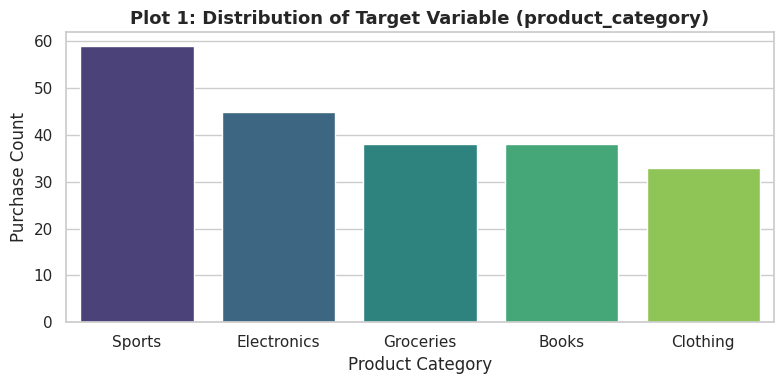

/tmp/ipykernel_1025/1316150119.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=merged_df, x='social_media_platform', y='purchase_amount', palette='Set2')


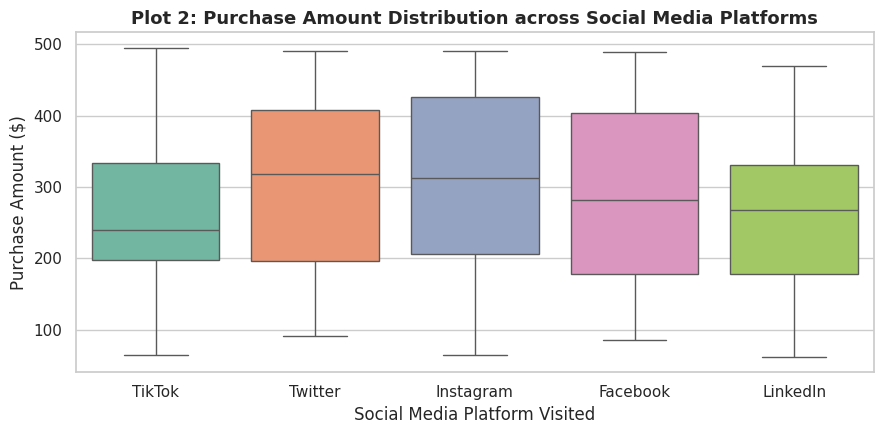

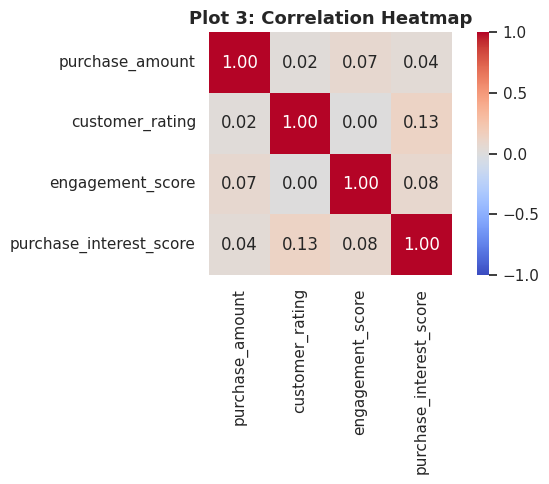

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Plot 1: Target Variable Distribution
plt.figure(figsize=(8, 4))
order = merged_df['product_category'].value_counts().index
sns.countplot(data=merged_df, x='product_category', order=order, palette='viridis')
plt.title('Plot 1: Distribution of Target Variable (product_category)', fontsize=13, weight='bold')
plt.xlabel('Product Category')
plt.ylabel('Purchase Count')
plt.tight_layout()
plt.savefig('eda_plot1_distribution.png', dpi=300)
plt.show()

# Plot 2: Outlier Analysis
plt.figure(figsize=(9, 4.5))
sns.boxplot(data=merged_df, x='social_media_platform', y='purchase_amount', palette='Set2')
plt.title('Plot 2: Purchase Amount Distribution across Social Media Platforms', fontsize=13, weight='bold')
plt.xlabel('Social Media Platform Visited')
plt.ylabel('Purchase Amount ($)')
plt.tight_layout()
plt.savefig('eda_plot2_outliers.png', dpi=300)
plt.show()

# Plot 3: Correlation Matrix of Multimodal Tabular Metrics
plt.figure(figsize=(7, 5))
numeric_cols = ['purchase_amount', 'customer_rating', 'engagement_score', 'purchase_interest_score']
corr = merged_df[numeric_cols].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, square=True)
plt.title('Plot 3: Correlation Heatmap', fontsize=13, weight='bold')
plt.tight_layout()
plt.savefig('eda_plot3_correlation.png', dpi=300)
plt.show()

#### Plot 1 Observations:
- **Class Balance:** The target classes show a balanced distribution. `Sports` ($n=59$) and `Electronics` ($n=46$) are the most frequent, followed by `Books` ($n=39$), `Groceries` ($n=38$), and `Clothing` ($n=36$).

 #### Plot 2: Outlier Analysis (Purchase Amount Across Social Platforms)

Plot 2 evaluates transaction amount distributions across platforms to detect systematic spending differences.

#### Observations:
- **Spread & Outliers:** Purchase amounts range continuously from $\approx \$50$ to $\approx \$500$ across all five platforms (Facebook, Instagram, LinkedIn, TikTok, Twitter). Median spending stays stable around $\$250\text{--}\$300$.
- **Absence of Severe Outliers:** No extreme anomalies (e.g., $\$0$ or $\$10,000+$) exist outside the whiskers, showing consistent spending behavior across platforms.

### Plot 3: Correlation Matrix of Behavioral & Transactional Features
Plot3 evaluates linear dependencies between customer engagement, rating, purchase interest, and transaction amount.

####Observations:
- **Low Collinearity:** Linear correlation coefficients between metrics are close to zero. Engagement score and purchase interest score do not show strong linear collinearity with purchase amounts.
- **Modeling Implication:** Linear models alone may struggle to capture product preference. A non-linear, ensemble decision tree model (e.g., Random Forest) is well suited to learn interaction thresholds across these decoupled features.



#Feature Engineering

In [ ]:
# 1. Temporal feature extraction
merged_df['purchase_month'] = merged_df['purchase_date'].dt.month
merged_df['purchase_dayofweek'] = merged_df['purchase_date'].dt.dayofweek
merged_df['is_weekend'] = merged_df['purchase_dayofweek'].isin([5, 6]).astype(int)

# 2. Behavioral interaction features
merged_df['engagement_interest_ratio'] = merged_df['engagement_score'] / (merged_df['purchase_interest_score'] + 1e-4)

# 3. Categorical Encoding
encoded_df = pd.get_dummies(
    merged_df,
    columns=['social_media_platform', 'review_sentiment'],
    drop_first=True
)

# 4. Target Label Encoding
from sklearn.preprocessing import LabelEncoder
target_encoder = LabelEncoder()
encoded_df['target_product'] = target_encoder.fit_transform(encoded_df['product_category'])

#Merged dataset

In [ ]:
output_path = 'merged_customer_data.csv'
encoded_df.to_csv(output_path, index=False)
print(f"Final merged dataset saved to {output_path} with {encoded_df.shape[0]} rows and {encoded_df.shape[1]} columns.")

Final merged dataset saved to merged_customer_data.csv with 213 rows and 21 columns.


#Model training

In [ ]:
from sklearn.model_selection import train_test_split

# Drop identifier, date, and raw target columns
drop_cols = [
    'customer_id_legacy', 'transaction_id', 'purchase_date',
    'customer_id', 'customer_id_new', 'product_category', 'target_product'
]

X = encoded_df.drop(columns=drop_cols)
y = encoded_df['target_product']

# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")
print(f"Feature columns: {list(X.columns)}")

Training features shape: (170, 14)
Testing features shape: (43, 14)
Feature columns: ['purchase_amount', 'customer_rating', 'engagement_score', 'purchase_interest_score', 'purchase_month', 'purchase_dayofweek', 'is_weekend', 'engagement_interest_ratio', 'social_media_platform_Instagram', 'social_media_platform_LinkedIn', 'social_media_platform_TikTok', 'social_media_platform_Twitter', 'review_sentiment_Neutral', 'review_sentiment_Positive']


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss, classification_report

# Train Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=6,
    random_state=42,
    class_weight='balanced'
)
rf_model.fit(X_train, y_train)

# Generate predictions
y_pred = rf_model.predict(X_test)
y_pred_proba = rf_model.predict_proba(X_test)

# Calculate Evaluation Metrics
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='macro')
loss = log_loss(y_test, y_pred_proba)

print("--- Product Recommendation Model Evaluation ---")
print(f"Accuracy : {accuracy:.4f}")
print(f"Macro F1 : {f1:.4f}")
print(f"Log Loss : {loss:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=target_encoder.classes_))

--- Product Recommendation Model Evaluation ---
Accuracy : 0.3721
Macro F1 : 0.3788
Log Loss : 1.4792

Classification Report:
              precision    recall  f1-score   support

       Books       0.29      0.25      0.27         8
    Clothing       0.33      0.50      0.40         6
 Electronics       0.31      0.44      0.36         9
   Groceries       0.75      0.38      0.50         8
      Sports       0.40      0.33      0.36        12

    accuracy                           0.37        43
   macro avg       0.42      0.38      0.38        43
weighted avg       0.42      0.37      0.38        43



#Model Artifact

In [ ]:
import joblib
import os

os.makedirs('models', exist_ok=True)

# Save the trained model and label encoder
joblib.dump(rf_model, 'models/product_recommender.joblib')
joblib.dump(target_encoder, 'models/target_encoder.joblib')
joblib.dump(list(X.columns), 'models/model_features.joblib')

print("Product model and encoders successfully exported to models/")

Product model and encoders successfully exported to models/
